# Psychiatric ER Boarding: 
Which Hospitals Have the Longest Mental Health ER Waits?

**Data:** CMS Hospital Compare — Timely and Effective Care + Hospital General Information

## Research Question
Which hospital characteristics predict the longest ER waits for mental health patients?


## Why It Matters
When mental health patients wait in the ER for a psychiatric bed ("boarding"),
it delays their care and crowds the ER for everyone else.

## Approach
1. Load the dataset built in SQL (`Boarding_Analysis_Dataset.ipynb`)
2. Inspect and clean the data
3. Explore the data
4. Feature engineering
5. Machine learning: logistic regression (can we predict the longest waits?)

## Load the Data

In [199]:
import pandas as pd
import numpy as np

In [200]:
df = pd.read_csv("../data/Processed/boarding_dataset.csv",
                 dtype={"facility_id": str})

## Inspect Data

In [201]:
df.shape # 4,658 rows and 44 columns

(4658, 44)

In [202]:
df.head()

,facility_id,wait_psych,n_psych_patients,wait_regular,n_regular_patients,er_volume,Facility ID,Facility Name,Address,City/Town,...,Count of READM Measures Better,Count of READM Measures No Different,Count of READM Measures Worse,READM Group Footnote,Pt Exp Group Measure Count,Count of Facility Pt Exp Measures,Pt Exp Group Footnote,TE Group Measure Count,Count of Facility TE Measures,TE Group Footnote
0,010001,NaN,NaN,212.0,396.0,very high,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,...,1,9,1,NaN,15,15,NaN,10,10,NaN
1,010005,242.0,30.0,143.0,1155.0,very high,010005,MARSHALL MEDICAL CENTERS,2505 U S HIGHWAY 431 NORTH,BOAZ,...,1,8,0,NaN,15,15,NaN,10,10,NaN
2,010006,218.0,13.0,147.0,328.0,high,010006,NORTH ALABAMA MEDICAL CENTER,1701 VETERANS DRIVE,FLORENCE,...,1,8,0,NaN,15,15,NaN,10,9,NaN
3,010007,242.0,57.0,130.0,1004.0,low,010007,MIZELL MEMORIAL HOSPITAL,702 N MAIN ST,OPP,...,0,3,2,NaN,15,5,NaN,10,7,NaN
4,010011,NaN,NaN,158.0,341.0,Not Available,010011,ST. VINCENT'S EAST,50 MEDICAL PARK EAST DRIVE,BIRMINGHAM,...,1,5,2,29.0,15,10,29.0,10,7,29.0


Each row is one hospital. Hospitals that don't report a wait time show `NaN`.

In [203]:
df.columns

Index(['facility_id', 'wait_psych', 'n_psych_patients', 'wait_regular',
       'n_regular_patients', 'er_volume', 'Facility ID', 'Facility Name',
       'Address', 'City/Town', 'State', 'ZIP Code', 'County/Parish',
       'Telephone Number', 'Hospital Type', 'Hospital Ownership',
       'Emergency Services',
       'Meets criteria for birthing friendly designation',
       'Hospital overall rating', 'Hospital overall rating footnote',
       'MORT Group Measure Count', 'Count of Facility MORT Measures',
       'Count of MORT Measures Better', 'Count of MORT Measures No Different',
       'Count of MORT Measures Worse', 'MORT Group Footnote',
       'Safety Group Measure Count', 'Count of Facility Safety Measures',
       'Count of Safety Measures Better',
       'Count of Safety Measures No Different',
       'Count of Safety Measures Worse', 'Safety Group Footnote',
       'READM Group Measure Count', 'Count of Facility READM Measures',
       'Count of READM Measures Better',
       

4,658 hospitals and 44 columns: 5 ER measures from tec (`wait_psych`, `n_psych_patients`, `wait_regular`, `n_regular_patients`, `er_volume`) plus the hospital information from hosp.

In [204]:
df.dtypes

facility_id                                          object
wait_psych                                          float64
n_psych_patients                                    float64
wait_regular                                        float64
n_regular_patients                                  float64
er_volume                                            object
Facility ID                                          object
Facility Name                                        object
Address                                              object
City/Town                                            object
State                                                object
ZIP Code                                              int64
County/Parish                                        object
Telephone Number                                     object
Hospital Type                                        object
Hospital Ownership                                   object
Emergency Services                      

The wait times are numbers, but the star rating and the quality measure counts are stored as text because CMS used "Not Available". These will be converted to numbers in cleaning. The other text columns (e.g., `er_volume`, `Hospital Type`, `Hospital Ownership`) are categories.

In [205]:
#summary stats for the number columns (mean, min, max, etc.)
df.describe()

,wait_psych,n_psych_patients,wait_regular,n_regular_patients,ZIP Code,MORT Group Footnote,Safety Group Footnote,READM Group Footnote,Pt Exp Group Footnote,TE Group Footnote
count,3023.000000,3023.000000,4081.000000,4081.000000,4658.000000,756.000000,1497.000000,585.000000,1365.000000,375.000000
mean,276.739663,33.832947,156.943396,589.835580,54403.336410,11.166667,8.094188,12.825641,8.182418,18.368000
std,187.761586,156.284175,50.838908,2828.182617,26878.221257,8.495811,6.713967,8.879927,6.771489,7.282169
min,41.000000,11.000000,42.000000,17.000000,603.000000,5.000000,5.000000,5.000000,5.000000,5.000000
25%,184.000000,14.000000,119.000000,349.000000,33175.250000,5.000000,5.000000,5.000000,5.000000,16.000000
50%,247.000000,19.000000,148.000000,375.000000,56066.500000,5.000000,5.000000,5.000000,5.000000,19.000000
75%,324.000000,26.000000,188.000000,406.000000,76243.000000,19.000000,5.000000,19.000000,5.000000,22.000000
max,6870.000000,4523.000000,413.000000,107371.000000,99929.000000,29.000000,29.000000,29.000000,29.000000,29.000000


The max `wait_psych` is 6,870 minutes, much higher than the 75% value (324),
so there are outliers. Because of that, the median is a better summary than the mean.

`wait_psych` is reported by 3,023 hospitals and `wait_regular` by 4,081.

In [206]:
df.info() #data type of each column and how many are not blank

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4658 entries, 0 to 4657
Data columns (total 44 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   facility_id                                       4658 non-null   object 
 1   wait_psych                                        3023 non-null   float64
 2   n_psych_patients                                  3023 non-null   float64
 3   wait_regular                                      4081 non-null   float64
 4   n_regular_patients                                4081 non-null   float64
 5   er_volume                                         4658 non-null   object 
 6   Facility ID                                       4658 non-null   object 
 7   Facility Name                                     4658 non-null   object 
 8   Address                                           4658 non-null   object 
 9   City/Town          

`info()` shows each column's type and how many hospitals have a value. Only 3,023 hospitals have `wait_psych` and 4,081 have `wait_regular`.

In [207]:
df["Hospital Type"].value_counts()

Hospital Type
Acute Care Hospitals                  3107
Critical Access Hospitals             1382
Childrens                               94
Rural Emergency Hospital                43
Acute Care - Department of Defense      32
Name: count, dtype: int64

There are 5 hospital types. Most are Acute Care (3,107) or Critical Access (1,382). Children's (94), Rural Emergency (43), and Department of Defense (32) hospitals are small groups.

In [208]:
#every state value, sorted A-Z, to spot typos or extra codes
df["State"].value_counts().sort_index()

State
AK     23
AL     87
AR     78
AS      1
AZ     84
CA    329
CO     86
CT     27
DC      7
DE      7
FL    184
GA    133
GU      2
HI     23
IA    112
ID     43
IL    172
IN    115
KS    132
KY     91
LA    112
MA     62
MD     46
ME     31
MI    127
MN    124
MO    103
MP      1
MS     97
MT     61
NC    102
ND     44
NE     90
NH     26
NJ     63
NM     40
NV     36
NY    154
OH    160
OK    122
OR     58
PA    153
PR     54
RI     10
SC     56
SD     58
TN     97
TX    401
UT     47
VA     84
VI      2
VT     14
WA     89
WI    124
WV     46
WY     28
Name: count, dtype: int64

56 codes: the 50 states, DC, and 5 US territories (AS, GU, MP, PR, VI). There are no typos or duplicate spellings. The territories need a decision before creating regions.

In [209]:
df["Hospital overall rating"].value_counts(dropna=False)

Hospital overall rating
Not Available    1596
3                 967
4                 909
2                 654
5                 334
1                 198
Name: count, dtype: int64

The star rating is 1–5, but 1,596 hospitals have "Not Available", which is why the column is stored as text.

In [210]:
df["Emergency Services"].value_counts()

Emergency Services
Yes    4297
No      361
Name: count, dtype: int64

4,297 hospitals have emergency services and 361 do not. This is across all 4,658 hospitals and will be checked again after hospitals missing a wait time are dropped.

In [211]:
df["er_volume"].value_counts()

er_volume
low              1657
medium            914
Not Available     832
very high         703
high              552
Name: count, dtype: int64

ER volume has 4 levels (low, medium, high, very high). Low is the most common (1,657). 832 hospitals have "Not Available".

In [212]:
df["Count of MORT Measures Worse"].value_counts(dropna=False)

Count of MORT Measures Worse
0                3497
Not Available     683
1                 373
2                  80
3                  18
4                   6
5                   1
Name: count, dtype: int64

Values are 0–5 plus "Not Available" (683). Most hospitals (3,497) have 0, meaning they are not worse than the national average on any mortality measure.

In [213]:
df["Hospital Ownership"].value_counts()

Hospital Ownership
Voluntary non-profit - Private                 2235
Proprietary                                     723
Government - Hospital District or Authority     510
Government - Local                              376
Voluntary non-profit - Other                    334
Voluntary non-profit - Church                   256
Physician                                        77
Government - State                               65
Government - Federal                             33
Department of Defense                            32
Tribal                                           17
Name: count, dtype: int64

There are 11 ownership types. Most hospitals are voluntary non-profit (private, 2,235), followed by proprietary (for-profit, 723). Some groups are very small (Tribal 17, Department of Defense 32).

In [214]:
#how many different values each column has (1 = every row is the same)
df.nunique().sort_values()

Meets criteria for birthing friendly designation       1
TE Group Measure Count                                 2
Pt Exp Group Measure Count                             2
MORT Group Measure Count                               2
Emergency Services                                     2
Safety Group Measure Count                             2
READM Group Measure Count                              2
Pt Exp Group Footnote                                  4
Count of Facility Pt Exp Measures                      4
TE Group Footnote                                      5
Hospital Type                                          5
Count of Safety Measures Worse                         5
READM Group Footnote                                   5
er_volume                                              5
MORT Group Footnote                                    5
Safety Group Footnote                                  6
Hospital overall rating                                6
Count of MORT Measures Worse   

`nunique()` counts how many different values each column has (blanks are not counted).
- `facility_id` has 4,658 unique values for 4,658 rows, so each hospital appears once.
- Birthing friendly has only 1 value, and the `Group Measure Count` columns have only 2, so they tell us little.
- `State` has 56 values (50 states, DC, and 5 territories).
- Contact columns (Address, Telephone, ZIP) are almost all unique, so they can't help predict anything.

## Data Cleaning 

### Replace "Not Available" with blanks

In [215]:
df = df.replace("Not Available", np.nan) #CMS writes "Not Available" as text, replacing it with NaN

In [216]:
df.isna().sum().sort_values(ascending=False)#count blanks in each column (most missing at the top)

TE Group Footnote                                   4283
READM Group Footnote                                4073
MORT Group Footnote                                 3902
Pt Exp Group Footnote                               3293
Safety Group Footnote                               3161
Hospital overall rating footnote                    2991
Meets criteria for birthing friendly designation    2395
n_psych_patients                                    1635
wait_psych                                          1635
Hospital overall rating                             1596
Count of Safety Measures Better                     1423
Count of Facility Safety Measures                   1423
Count of Safety Measures Worse                      1423
Count of Safety Measures No Different               1423
Count of Facility Pt Exp Measures                   1304
er_volume                                            832
Count of MORT Measures Worse                         683
Count of MORT Measures No Diffe

After replacing "Not Available" with NaN:
- 1,635 hospitals are missing `wait_psych` and `n_psych_patients`
- 577 hospitals are missing `wait_regular` and `n_regular_patients`
- Among the hospital features, star rating (1,596) and the safety measures (1,423)
  have the most missing values
- Footnote columns are mostly blank

### Drop columns not needed for the analysis

In [217]:
dup_id = ["Facility ID"] #duplicate hospital ID (same as facility_id)

In [218]:
contact = ["Address", "City/Town", "ZIP Code", "County/Parish", "Telephone Number"]# Keeping State

In [219]:
#footnotes (codes explaining missing values, not real data)
footnotes = ["Hospital overall rating footnote", "MORT Group Footnote",
            "Safety Group Footnote", "READM Group Footnote",
            "Pt Exp Group Footnote", "TE Group Footnote"]

In [220]:
##group measure counts (only one number + "Not Available", so they tell us nothing about the hospital)
group_counts = ["MORT Group Measure Count", "Safety Group Measure Count",
               "READM Group Measure Count", "Pt Exp Group Measure Count",
               "TE Group Measure Count"]

In [221]:
#quality counts not needed (keeping only the "Worse" counts)
extra_counts = ["Count of Facility MORT Measures", "Count of MORT Measures Better",
               "Count of MORT Measures No Different",
               "Count of Facility Safety Measures", "Count of Safety Measures Better",
               "Count of Safety Measures No Different",
               "Count of Facility READM Measures", "Count of READM Measures Better",
               "Count of Facility Pt Exp Measures", "Count of Facility TE Measures","Count of READM Measures No Different"]

In [222]:
#birthing friendly (about maternity care, not related to ER waits)
birthing = ["Meets criteria for birthing friendly designation"]

In [223]:
df = df.drop(columns=dup_id + contact + footnotes + group_counts + birthing +extra_counts)

In [224]:
#check the new size
df.shape

(4658, 15)

### Convert text to numbers

In [225]:
#these columns hold numbers but are stored as text (object)
num_cols = ["Hospital overall rating",
            "Count of MORT Measures Worse",
            "Count of Safety Measures Worse",
            "Count of READM Measures Worse"]

df[num_cols] = df[num_cols].apply(pd.to_numeric)


In [226]:
df[num_cols] = df[num_cols].apply(pd.to_numeric)

#check the types again
df.dtypes

facility_id                        object
wait_psych                        float64
n_psych_patients                  float64
wait_regular                      float64
n_regular_patients                float64
er_volume                          object
Facility Name                      object
State                              object
Hospital Type                      object
Hospital Ownership                 object
Emergency Services                 object
Hospital overall rating           float64
Count of MORT Measures Worse      float64
Count of Safety Measures Worse    float64
Count of READM Measures Worse     float64
dtype: object

The star rating and the three "Worse" counts were converted from text to numbers.

### Who is missing the mental health wait time?

In [227]:
#hospitals that do NOT report the mental health wait time
missing = df[df["wait_psych"].isna()]

#how many
missing.shape

(1635, 15)

In [228]:
#hospital types among the missing
missing["Hospital Type"].value_counts()

Hospital Type
Acute Care Hospitals                  876
Critical Access Hospitals             590
Childrens                              94
Rural Emergency Hospital               43
Acute Care - Department of Defense     32
Name: count, dtype: int64

In [229]:
#% of each hospital type that is missing the wait time
(df["wait_psych"].isna().groupby(df["Hospital Type"]).mean() * 100).round(1).sort_values(ascending=False)

Hospital Type
Acute Care - Department of Defense    100.0
Childrens                             100.0
Rural Emergency Hospital              100.0
Critical Access Hospitals              42.7
Acute Care Hospitals                   28.2
Name: wait_psych, dtype: float64

Department of Defense, Children's, and Rural Emergency hospitals are 100% missing
the mental health wait time, so they are fully excluded from the analysis.
Critical Access Hospitals (small, rural) are missing 42.7%, compared with 28.2%
for Acute Care Hospitals. After dropping missing wait times, the results mainly
describe Acute Care Hospitals, and small rural hospitals are underrepresented.

### Drop hospitals missing the wait time

In [230]:
#drop hospitals missing the mental health wait time (our target comes from this)
#subset= only looks at wait_psych, so other blanks don't cause drops
df = df.dropna(subset=["wait_psych"])

#check the new size
df.shape

(3023, 15)

3,023 hospitals remain after dropping those missing the mental health wait time.

In [231]:
#count blanks again now that only hospitals with a wait time are left
df.isna().sum().sort_values(ascending=False)

Hospital overall rating           614
Count of Safety Measures Worse    607
er_volume                         189
Count of MORT Measures Worse      189
Count of READM Measures Worse     116
facility_id                         0
wait_psych                          0
n_psych_patients                    0
wait_regular                        0
n_regular_patients                  0
Facility Name                       0
State                               0
Hospital Type                       0
Hospital Ownership                  0
Emergency Services                  0
dtype: int64

After dropping missing wait times, both wait times are complete. Star rating (614) and safety measures (607) are missing for about 20% of hospitals, ER volume and mortality measures (189) for about 6%, and readmission measures (116) for about 4%. These will be filled in during modeling, after the train/test split.

In [232]:
df.columns

Index(['facility_id', 'wait_psych', 'n_psych_patients', 'wait_regular',
       'n_regular_patients', 'er_volume', 'Facility Name', 'State',
       'Hospital Type', 'Hospital Ownership', 'Emergency Services',
       'Hospital overall rating', 'Count of MORT Measures Worse',
       'Count of Safety Measures Worse', 'Count of READM Measures Worse'],
      dtype='object')

### Emergency services and territories

In [233]:
#recheck emergency services now that only hospitals with a wait time are left
df["Emergency Services"].value_counts()

Emergency Services
Yes    2901
No      122
Name: count, dtype: int64

After dropping missing wait times, 2,901 hospitals have emergency services
and 122 do not. Because almost all hospitals are the same, this column adds little
information for the model and is dropped.

In [234]:
#drop emergency services
df = df.drop(columns=["Emergency Services"])
df.shape

(3023, 14)

In [235]:
#territory hospitals left after dropping missing waits
territories = ["AS", "GU", "MP", "PR", "VI"]
df[df["State"].isin(territories)]["State"].value_counts()

State
PR    4
GU    1
Name: count, dtype: int64

In [236]:
#drop the 5 territory hospitals (too few to form their own region)
df = df[~df["State"].isin(territories)]
df.shape

(3018, 14)

Only 5 territory hospitals remain (4 in PR, 1 in GU). They are too few to form
their own region, so they are dropped. The analysis covers the 50 states and DC.

### Check the sample-size columns

In [237]:
#median "regular patients" for each ER volume level
df.groupby("er_volume")["n_regular_patients"].median()

er_volume
high         382.0
low          367.0
medium       380.0
very high    382.0
Name: n_regular_patients, dtype: float64

The median of `n_regular_patients` is almost the same (367–382) across all ER volume
levels. If it measured how busy the ER is, it would rise from low to very high.
This suggests the CMS "Sample" column is the number of cases sampled for the measure,
not the number of patients the ER saw. `er_volume` is used as the measure of how busy
the ER is, and both sample columns are dropped.

In [238]:
#drop the sample-size columns (they reflect CMS sampling, not hospital size)
df = df.drop(columns=["n_regular_patients", "n_psych_patients"])
df.shape

(3018, 12)

### Final checks

In [239]:
#final check of the cleaned data
print(df.shape)
print(df.isna().sum())
df.dtypes

(3018, 12)
facility_id                         0
wait_psych                          0
wait_regular                        0
er_volume                         186
Facility Name                       0
State                               0
Hospital Type                       0
Hospital Ownership                  0
Hospital overall rating           611
Count of MORT Measures Worse      189
Count of Safety Measures Worse    605
Count of READM Measures Worse     116
dtype: int64


facility_id                        object
wait_psych                        float64
wait_regular                      float64
er_volume                          object
Facility Name                      object
State                              object
Hospital Type                      object
Hospital Ownership                 object
Hospital overall rating           float64
Count of MORT Measures Worse      float64
Count of Safety Measures Worse    float64
Count of READM Measures Worse     float64
dtype: object

In [240]:
#each hospital should appear only once (0 = no repeats)
df["facility_id"].duplicated().sum()

np.int64(0)

### Cleaning summary
- Replaced "Not Available" with blanks
- Dropped 29 columns not needed (duplicate ID, contact info, footnotes, redundant counts, birthing friendly)
- Converted the star rating and "Worse" counts from text to numbers
- Dropped 1,635 hospitals missing the mental health wait time (Department of Defense, Children's, and Rural Emergency hospitals are fully excluded; Critical Access hospitals are underrepresented)
- Dropped Emergency Services (96% "Yes")
- Dropped 5 territory hospitals (too few for their own region)
- Dropped the sample-size columns (they reflect CMS sampling, not hospital size)
- No hospital appears twice

Final dataset: 3,018 hospitals and 12 columns. Remaining blanks will be filled during modeling.

## Exploratory Data Analysis

In [241]:
import matplotlib.pyplot as plt
import seaborn as sns

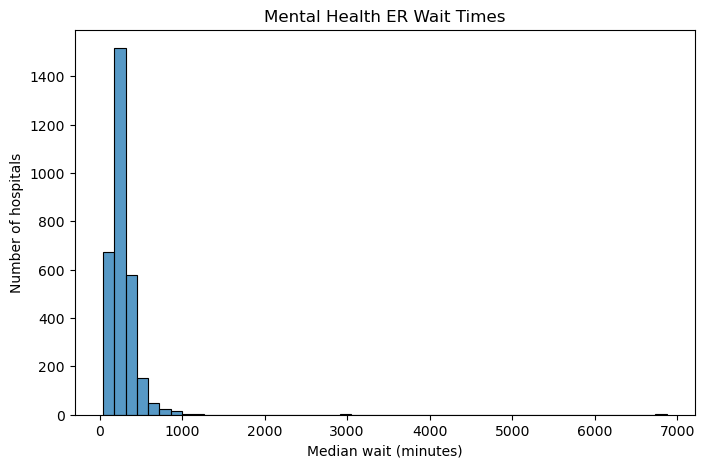

In [242]:
#histogram of mental health ER wait times
#bins=50 splits the wait times into 50 bars
plt.figure(figsize=(8, 5))
sns.histplot(df["wait_psych"], bins=50)
plt.title("Mental Health ER Wait Times")
plt.xlabel("Median wait (minutes)")
plt.ylabel("Number of hospitals")
plt.savefig("../figures/01_wait_psych_hist.png", dpi=150, bbox_inches="tight")
plt.show()

Mental health ER wait times are right-skewed. Most hospitals are under about
500 minutes, but a few extreme outliers (near 3,000 and 7,000 minutes) stretch the chart. 

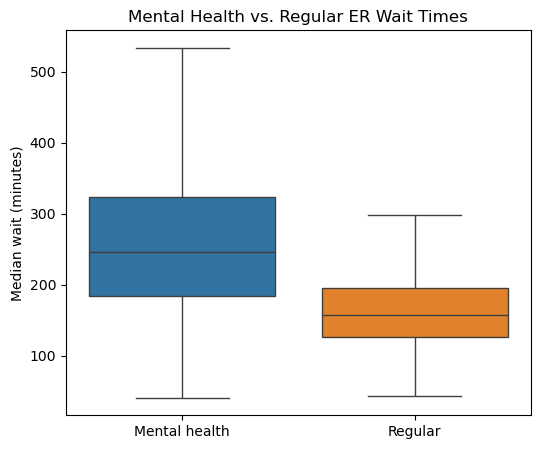

In [243]:
#compare mental health and regular ER wait times (box plot)
#showfliers=False hides the extreme outliers so the boxes are readable
plt.figure(figsize=(6, 5))
sns.boxplot(data=df[["wait_psych", "wait_regular"]],showfliers=False)
plt.title("Mental Health vs. Regular ER Wait Times")
plt.ylabel("Median wait (minutes)")
plt.xticks([0, 1], ["Mental health", "Regular"])
plt.savefig("../figures/02_psych_vs_regular.png", dpi=150, bbox_inches="tight")
plt.show()

Mental health patients wait longer than regular ER patients at the same hospitals.
The median mental health wait is about 250 minutes vs. about 155 minutes for regular
patients, and mental health waits vary much more across hospitals (taller box).
Extreme outliers are hidden in this chart to make the boxes readable.

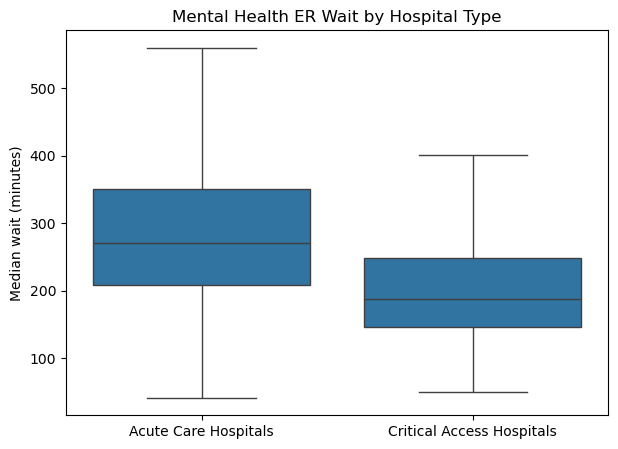

In [244]:
#mental health wait by hospital type
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Hospital Type", y="wait_psych", showfliers=False)
plt.title("Mental Health ER Wait by Hospital Type")
plt.xlabel("")
plt.ylabel("Median wait (minutes)")
plt.savefig("../figures/03_wait_by_type.png", dpi=150, bbox_inches="tight")
plt.show()

Acute Care hospitals have longer mental health ER waits (median about 270 minutes)
than Critical Access hospitals (about 190 minutes), and their waits vary more.
Critical Access hospitals are underrepresented because many did not report
the wait time, so this comparison should be read with caution.

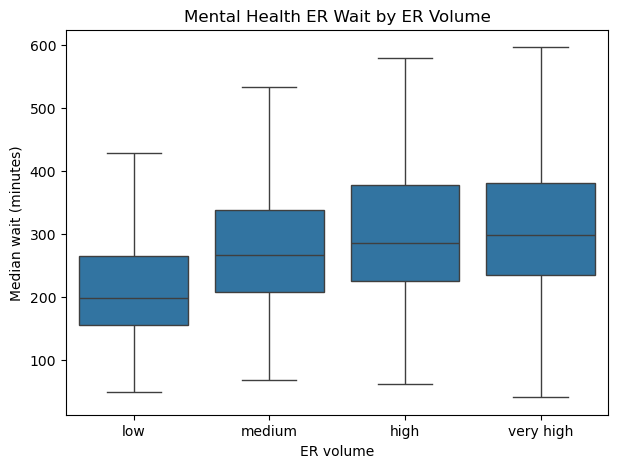

In [245]:
#mental health wait by ER volume (ordered from low to very high)
order = ["low", "medium", "high", "very high"]
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="er_volume", y="wait_psych", order=order, showfliers=False)
plt.title("Mental Health ER Wait by ER Volume")
plt.xlabel("ER volume")
plt.ylabel("Median wait (minutes)")
plt.savefig("../figures/04_wait_by_volume.png", dpi=150, bbox_inches="tight")
plt.show()

Mental health ER waits increase as ER volume increases, from a median of about
200 minutes at low-volume ERs to about 300 minutes at very-high-volume ERs.
The biggest jump is from low to medium. ER volume looks like a useful feature
for predicting the longest waits.

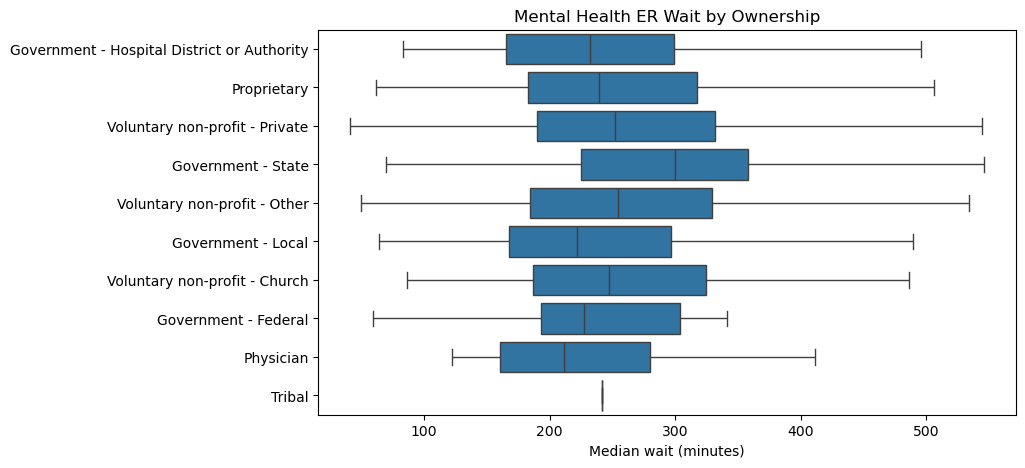

In [246]:
#mental health wait by ownership type
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="wait_psych", y="Hospital Ownership", showfliers=False)
plt.title("Mental Health ER Wait by Ownership")
plt.xlabel("Median wait (minutes)")
plt.ylabel("")
plt.savefig("../figures/05_wait_by_ownership.png", dpi=150, bbox_inches="tight")
plt.show()

In [295]:
#ownership counts after cleaning (3,018 hospitals)
df["Hospital Ownership"].value_counts()

Hospital Ownership
Voluntary non-profit - Private                 1566
Proprietary                                     417
Government - Hospital District or Authority     307
Voluntary non-profit - Other                    237
Government - Local                              234
Voluntary non-profit - Church                   196
Government - State                               38
Government - Federal                             12
Physician                                        10
Tribal                                            1
Name: count, dtype: int64

Most ownership types have similar mental health waits (medians about 220–260 minutes),
with heavily overlapping boxes. State government hospitals have the highest median
(about 300 minutes). Some groups are very small (Tribal 1, Physician 10, Federal 12),
so they will be combined into an "Other" group in feature engineering.
Ownership looks less important than ER volume.

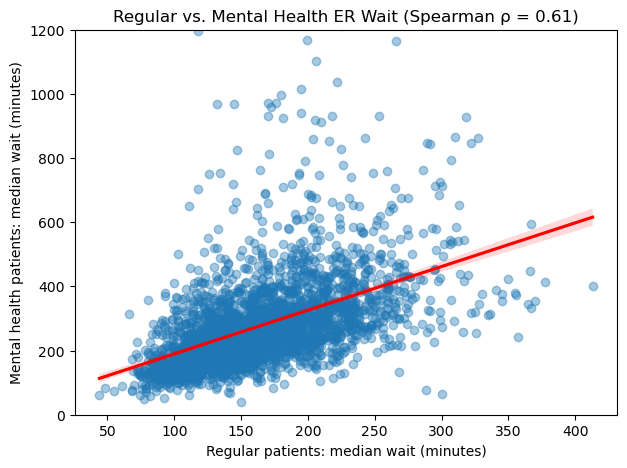

In [298]:
#regular vs. mental health wait, with a trend line and Spearman correlation
#Spearman is rank-based, so it isn't thrown off by the extreme outliers
rho = df["wait_regular"].corr(df["wait_psych"], method="spearman")

#each dot is one hospital; the red line shows the overall direction
plt.figure(figsize=(7, 5))
sns.regplot(data=df, x="wait_regular", y="wait_psych",
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.ylim(0, 1200)
plt.title(f"Regular vs. Mental Health ER Wait (Spearman ρ = {rho:.2f})")
plt.xlabel("Regular patients: median wait (minutes)")
plt.ylabel("Mental health patients: median wait (minutes)")
plt.savefig("../figures/06_regular_vs_psych.png", dpi=150, bbox_inches="tight")
plt.show()


Hospitals with longer regular ER waits tend to have longer mental health waits
(Spearman ρ = 0.61, a fairly strong positive relationship). The red line shows the
upward trend, but there is still a lot of scatter, especially at longer regular waits.
`wait_regular` looks like one of the strongest features for the model.

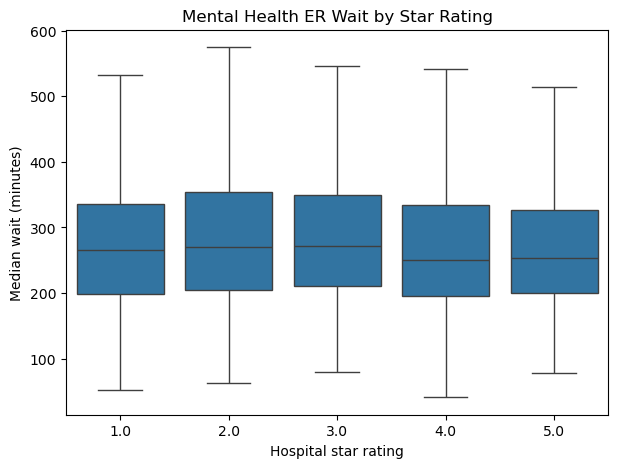

In [299]:
#mental health wait by hospital star rating (1-5)
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Hospital overall rating", y="wait_psych", showfliers=False)
plt.title("Mental Health ER Wait by Star Rating")
plt.xlabel("Hospital star rating")
plt.ylabel("Median wait (minutes)")
plt.savefig("../figures/07_wait_by_rating.png", dpi=150, bbox_inches="tight")
plt.show()
